In [1]:

from pathlib import Path

# Update this path according to your actual dataset location
DATASET_ROOT = Path(r"D:\brain tumour\brisc2025")

# Define paths according to your actual folder structure
TRAIN_IMAGES = DATASET_ROOT / "segmentation_task" / "train" / "images"
TRAIN_MASKS = DATASET_ROOT / "segmentation_task" / "train" / "masks"

TEST_IMAGES = DATASET_ROOT / "segmentation_task" / "test" / "images"
TEST_MASKS = DATASET_ROOT / "segmentation_task" / "test" / "masks"

# Check all required folders
folders = {
    "Training Images": TRAIN_IMAGES,
    "Training Masks": TRAIN_MASKS,
    "Testing Images": TEST_IMAGES,
    "Testing Masks": TEST_MASKS
}

print("BRISC2025 SEGMENTATION DATASET AUDIT")
print("=" * 45)

for name, folder in folders.items():
    print(f"{name}: {'Found' if folder.exists() else 'NOT FOUND'}")

    if folder.exists():
        files = [f for f in folder.iterdir() if f.is_file()]
        print(f"Total files: {len(files)}")

print("\n" + "=" * 45)

# Display sample filenames
for name, folder in folders.items():
    if folder.exists():
        files = sorted([f.name for f in folder.iterdir() if f.is_file()])

        print(f"\n{name} - First 5 files:")
        for filename in files[:5]:
            print(filename)


BRISC2025 SEGMENTATION DATASET AUDIT
Training Images: Found
Total files: 3933
Training Masks: Found
Total files: 3933
Testing Images: Found
Total files: 860
Testing Masks: Found
Total files: 860


Training Images - First 5 files:
brisc2025_train_00001_gl_ax_t1.jpg
brisc2025_train_00002_gl_ax_t1.jpg
brisc2025_train_00003_gl_ax_t1.jpg
brisc2025_train_00004_gl_ax_t1.jpg
brisc2025_train_00005_gl_ax_t1.jpg

Training Masks - First 5 files:
brisc2025_train_00001_gl_ax_t1.png
brisc2025_train_00002_gl_ax_t1.png
brisc2025_train_00003_gl_ax_t1.png
brisc2025_train_00004_gl_ax_t1.png
brisc2025_train_00005_gl_ax_t1.png

Testing Images - First 5 files:
brisc2025_test_00001_gl_ax_t1.jpg
brisc2025_test_00002_gl_ax_t1.jpg
brisc2025_test_00003_gl_ax_t1.jpg
brisc2025_test_00004_gl_ax_t1.jpg
brisc2025_test_00005_gl_ax_t1.jpg

Testing Masks - First 5 files:
brisc2025_test_00001_gl_ax_t1.png
brisc2025_test_00002_gl_ax_t1.png
brisc2025_test_00003_gl_ax_t1.png
brisc2025_test_00004_gl_ax_t1.png
brisc2025_test_0

In [2]:

def verify_image_mask_pairs(image_folder, mask_folder, dataset_name):

    image_files = {
        file.stem for file in image_folder.iterdir()
        if file.is_file()
    }

    mask_files = {
        file.stem for file in mask_folder.iterdir()
        if file.is_file()
    }

    missing_masks = image_files - mask_files
    missing_images = mask_files - image_files

    print(f"\n{dataset_name} PAIRING CHECK")
    print("-" * 40)

    print("Total images:", len(image_files))
    print("Total masks:", len(mask_files))

    print("Images without masks:", len(missing_masks))
    print("Masks without images:", len(missing_images))

    if not missing_masks and not missing_images:
        print("STATUS: All image-mask pairs matched!")
    else:
        print("STATUS: Pairing issues found.")

        if missing_masks:
            print("\nImages without matching masks:")
            print(sorted(missing_masks)[:10])

        if missing_images:
            print("\nMasks without matching images:")
            print(sorted(missing_images)[:10])


# Verify training dataset
verify_image_mask_pairs(
    TRAIN_IMAGES,
    TRAIN_MASKS,
    "TRAINING DATASET"
)

# Verify testing dataset
verify_image_mask_pairs(
    TEST_IMAGES,
    TEST_MASKS,
    "TESTING DATASET"
)



TRAINING DATASET PAIRING CHECK
----------------------------------------
Total images: 3933
Total masks: 3933
Images without masks: 0
Masks without images: 0
STATUS: All image-mask pairs matched!

TESTING DATASET PAIRING CHECK
----------------------------------------
Total images: 860
Total masks: 860
Images without masks: 0
Masks without images: 0
STATUS: All image-mask pairs matched!



Sample 1: brisc2025_train_03687_pi_ax_t1.jpg
Image size: (512, 512)
Image mode: RGB
Mask size: (512, 512)
Mask mode: L
Mask pixel values: [  0   1   2   3   4   5   7 249 250 251 252 253 254 255]

Sample 2: brisc2025_train_00457_gl_co_t1.jpg
Image size: (512, 512)
Image mode: L
Mask size: (512, 512)
Mask mode: L
Mask pixel values: [  0   1   2   3   4   5 249 250 251 252 253 254 255]

Sample 3: brisc2025_train_00103_gl_ax_t1.jpg
Image size: (512, 512)
Image mode: L
Mask size: (512, 512)
Mask mode: L
Mask pixel values: [  0   1   2   3   4   5   6 248 249 250 251 252 253 254 255]


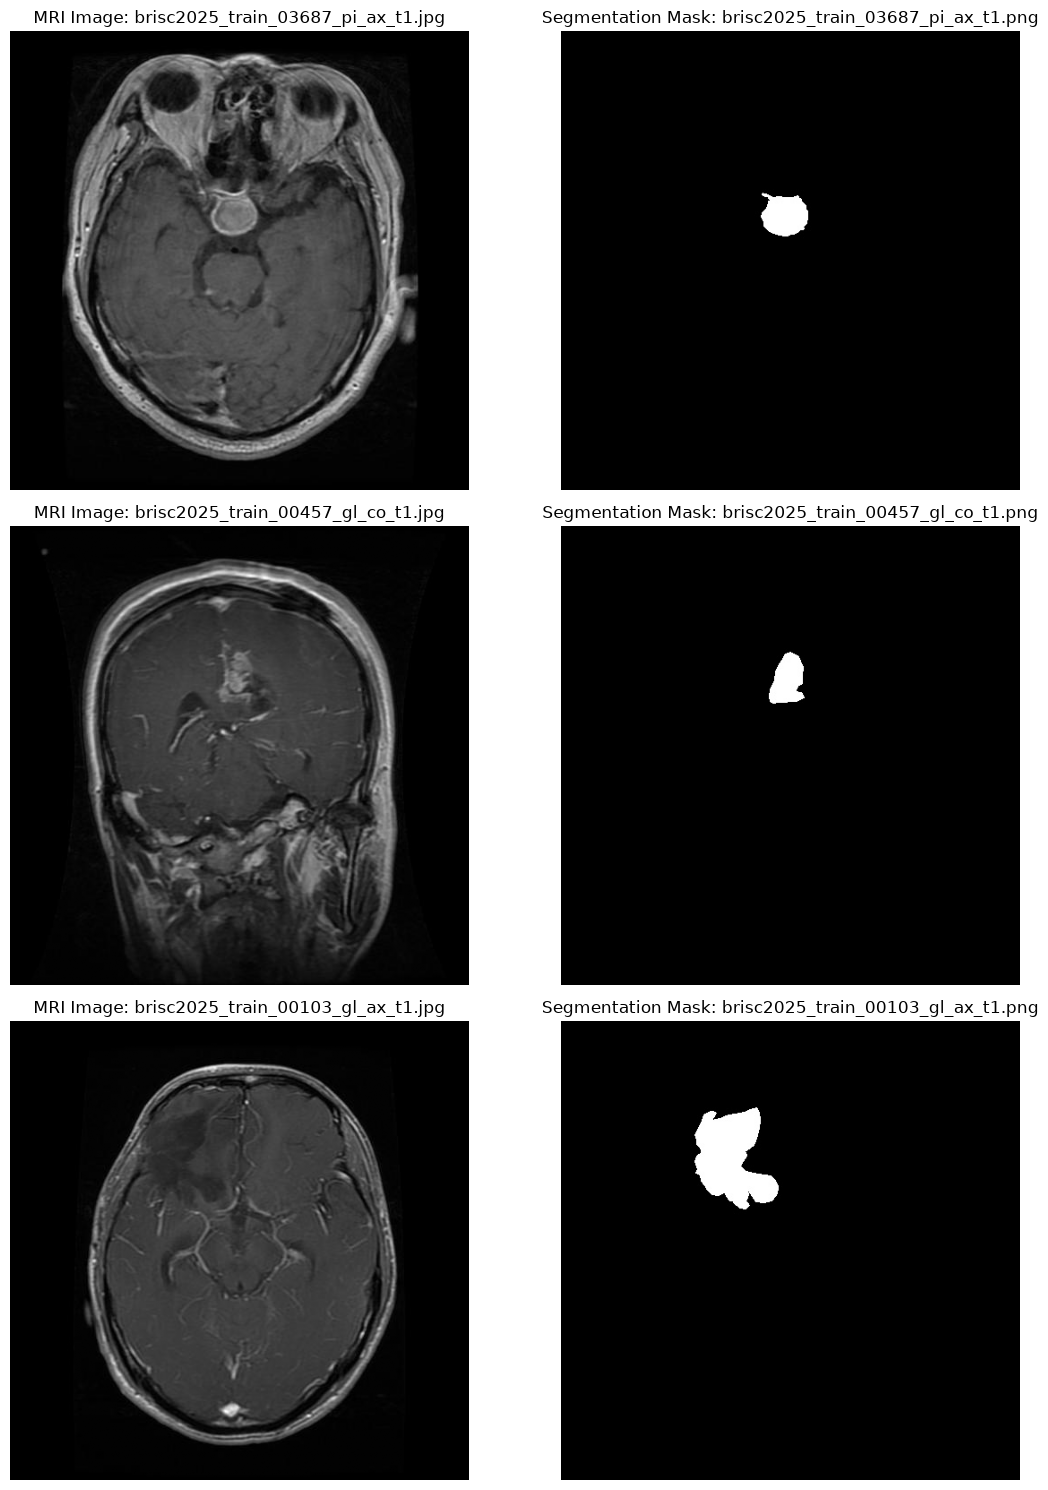

In [3]:

import random
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

# Reproducible random samples
random.seed(42)

# Get matching image filenames
image_files = sorted([
    f for f in TRAIN_IMAGES.iterdir()
    if f.is_file() and (TRAIN_MASKS / f"{f.stem}.png").exists()
])

# Select 3 random samples
samples = random.sample(image_files, 3)

fig, axes = plt.subplots(3, 2, figsize=(12, 15))

for i, image_path in enumerate(samples):

    mask_path = TRAIN_MASKS / f"{image_path.stem}.png"

    # Load image and mask
    image = Image.open(image_path)
    mask = Image.open(mask_path)

    image_array = np.array(image)
    mask_array = np.array(mask)

    # Display MRI image
    axes[i, 0].imshow(image_array, cmap="gray")
    axes[i, 0].set_title(f"MRI Image: {image_path.name}")
    axes[i, 0].axis("off")

    # Display segmentation mask
    axes[i, 1].imshow(mask_array, cmap="gray")
    axes[i, 1].set_title(f"Segmentation Mask: {mask_path.name}")
    axes[i, 1].axis("off")

    # Print image information
    print(f"\nSample {i+1}: {image_path.name}")
    print("Image size:", image.size)
    print("Image mode:", image.mode)
    print("Mask size:", mask.size)
    print("Mask mode:", mask.mode)

    if mask_array.ndim == 2:
        print("Mask pixel values:", np.unique(mask_array)[:20])
    else:
        print("Unique mask colors:", len(np.unique(
            mask_array.reshape(-1, mask_array.shape[-1]), axis=0
        )))

plt.tight_layout()
plt.show()



brisc2025_train_03687_pi_ax_t1.jpg
Unique mask values: [  0   1   2   3   4   5   7 249 250 251 252 253 254 255]
Foreground pixels: 1918
Background pixels: 260226
Tumor area (%): 0.732

brisc2025_train_00457_gl_co_t1.jpg
Unique mask values: [  0   1   2   3   4   5 249 250 251 252 253 254 255]
Foreground pixels: 1639
Background pixels: 260505
Tumor area (%): 0.625

brisc2025_train_00103_gl_ax_t1.jpg
Unique mask values: [  0   1   2   3   4   5   6 248 249 250 251 252 253 254 255]
Foreground pixels: 6578
Background pixels: 255566
Tumor area (%): 2.509


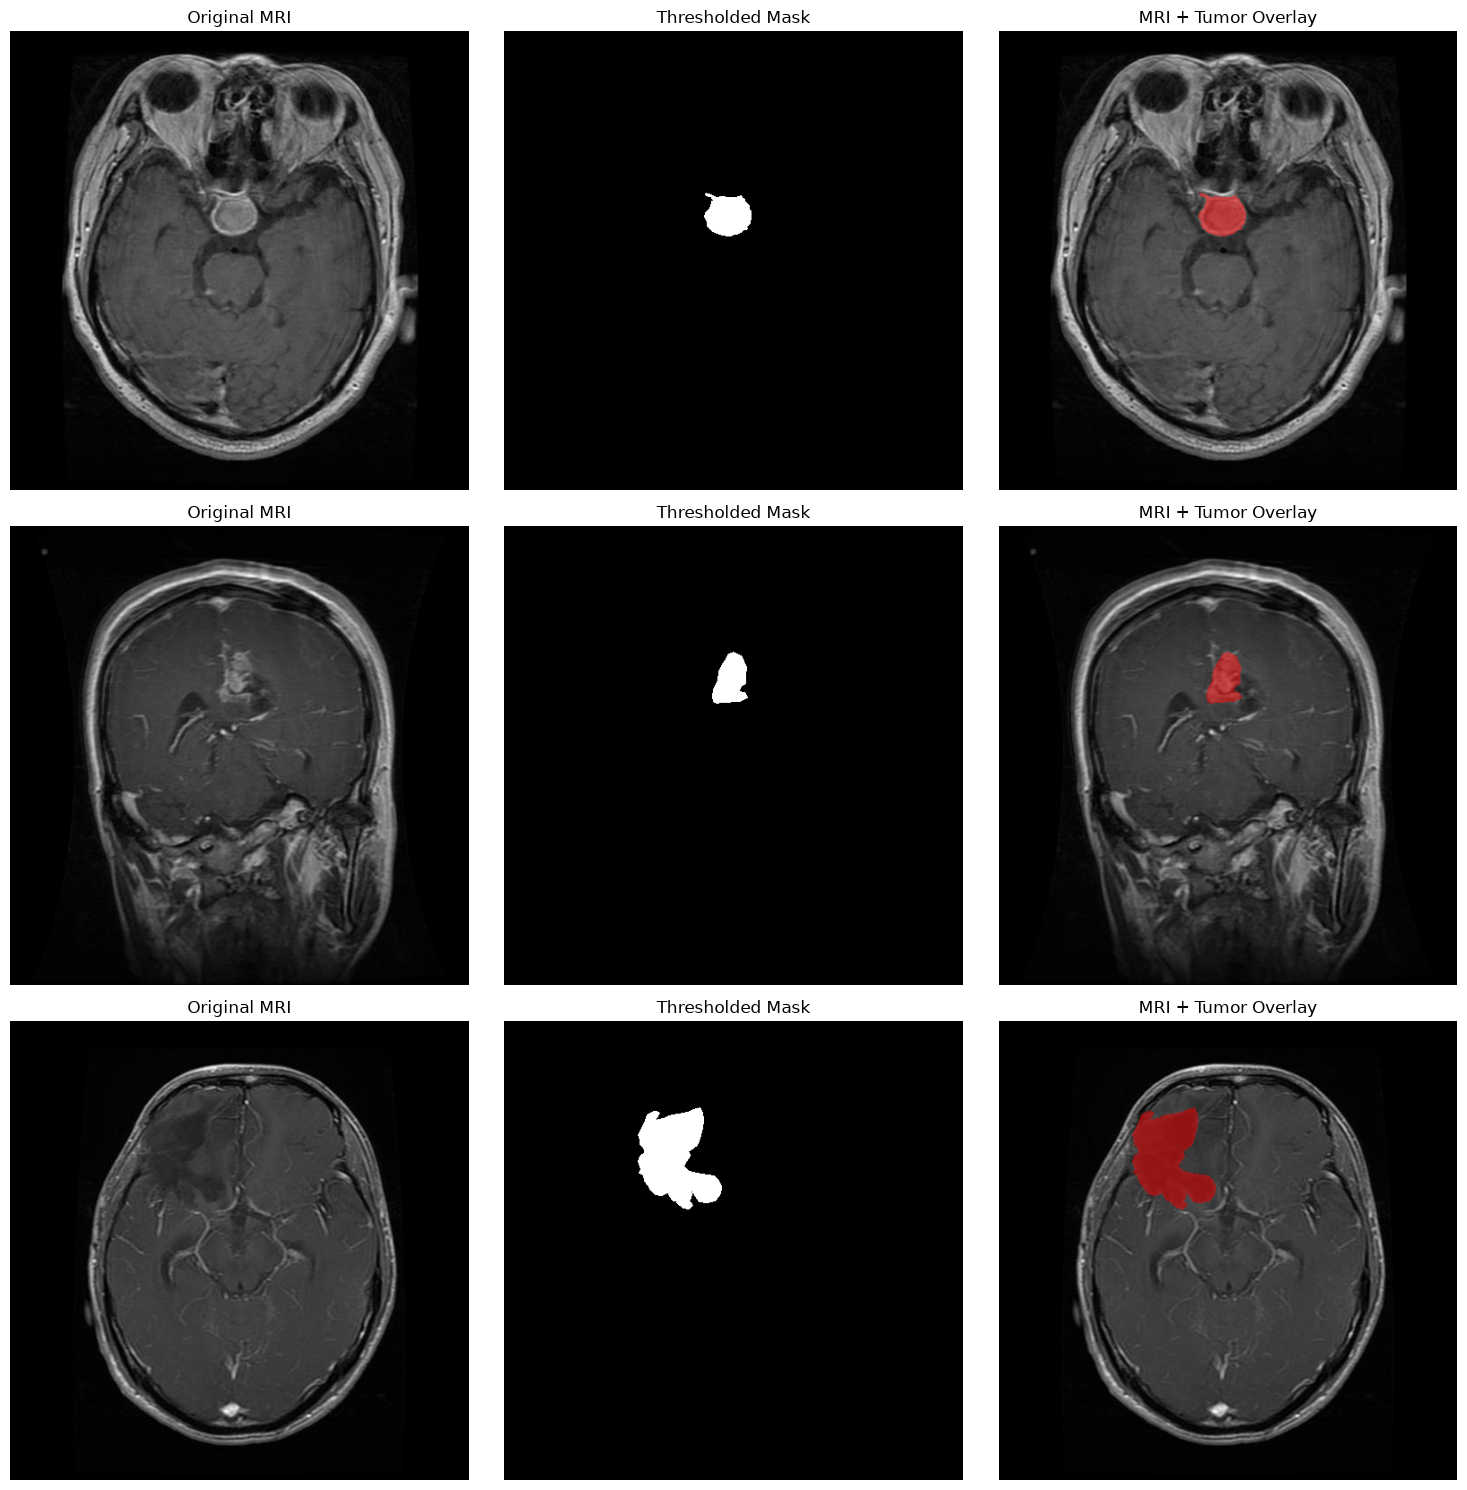

In [4]:

import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

fig, axes = plt.subplots(len(samples), 3, figsize=(15, 5 * len(samples)))

for i, image_path in enumerate(samples):

    mask_path = TRAIN_MASKS / f"{image_path.stem}.png"

    # Load image and grayscale mask
    image = Image.open(image_path).convert("RGB")
    mask = Image.open(mask_path).convert("L")

    image_array = np.array(image)
    mask_array = np.array(mask)

    # Exploratory threshold (not final preprocessing)
    binary_mask = mask_array >= 128

    # Pixel value analysis
    values, counts = np.unique(mask_array, return_counts=True)

    print(f"\n{image_path.name}")
    print("Unique mask values:", values)
    print("Foreground pixels:", np.sum(binary_mask))
    print("Background pixels:", np.sum(~binary_mask))
    print("Tumor area (%):", round(binary_mask.mean() * 100, 3))

    # Original MRI
    axes[i, 0].imshow(image_array)
    axes[i, 0].set_title("Original MRI")

    # Binary mask
    axes[i, 1].imshow(binary_mask, cmap="gray")
    axes[i, 1].set_title("Thresholded Mask")

    # Overlay mask on MRI
    axes[i, 2].imshow(image_array)
    axes[i, 2].imshow(
        np.ma.masked_where(~binary_mask, binary_mask),
        cmap="autumn",
        alpha=0.5
    )
    axes[i, 2].set_title("MRI + Tumor Overlay")

    for ax in axes[i]:
        ax.axis("off")

plt.tight_layout()
plt.show()


In [5]:

from collections import Counter
from PIL import Image
import numpy as np

def analyze_masks(mask_folder, dataset_name):

    mask_files = sorted([
        f for f in mask_folder.iterdir()
        if f.is_file()
    ])

    pixel_values = Counter()
    empty_masks = []
    dimensions = Counter()
    foreground_percentages = []

    for mask_path in mask_files:

        with Image.open(mask_path) as mask:
            mask_array = np.array(mask.convert("L"))

        dimensions[mask_array.shape] += 1

        # Count all pixel values
        values, counts = np.unique(
            mask_array, return_counts=True
        )

        pixel_values.update(
            dict(zip(values.tolist(), counts.tolist()))
        )

        # Exploratory threshold
        binary_mask = mask_array >= 128

        foreground_pixels = np.sum(binary_mask)

        if foreground_pixels == 0:
            empty_masks.append(mask_path.name)

        foreground_percentages.append(
            binary_mask.mean() * 100
        )

    print(f"\n{dataset_name} MASK ANALYSIS")
    print("=" * 45)

    print("Total masks:", len(mask_files))
    print("Empty masks:", len(empty_masks))
    print("Image dimensions:", dimensions)

    print("\nUnique pixel values:")
    print(sorted(pixel_values.keys()))

    print("\nForeground area statistics:")
    print("Minimum (%):", round(min(foreground_percentages), 4))
    print("Maximum (%):", round(max(foreground_percentages), 4))
    print("Average (%):", round(np.mean(foreground_percentages), 4))
    print("Median (%):", round(np.median(foreground_percentages), 4))

    if empty_masks:
        print("\nFirst 10 empty masks:")
        print(empty_masks[:10])


analyze_masks(TRAIN_MASKS, "TRAINING")
analyze_masks(TEST_MASKS, "TESTING")



TRAINING MASK ANALYSIS
Total masks: 3933
Empty masks: 0
Image dimensions: Counter({(512, 512): 3766, (256, 256): 25, (225, 225): 8, (442, 442): 4, (500, 455): 3, (237, 213): 2, (510, 485): 2, (554, 554): 2, (223, 200): 2, (251, 201): 2, (237, 212): 2, (395, 341): 2, (474, 474): 2, (270, 250): 1, (546, 472): 1, (427, 441): 1, (605, 507): 1, (345, 338): 1, (398, 369): 1, (650, 591): 1, (398, 351): 1, (377, 341): 1, (624, 491): 1, (358, 314): 1, (307, 257): 1, (345, 300): 1, (340, 291): 1, (354, 318): 1, (341, 315): 1, (306, 278): 1, (522, 513): 1, (401, 312): 1, (412, 300): 1, (251, 205): 1, (249, 204): 1, (342, 323): 1, (216, 216): 1, (372, 341): 1, (326, 273): 1, (337, 305): 1, (410, 304): 1, (243, 208): 1, (252, 200): 1, (480, 480): 1, (219, 224): 1, (235, 200): 1, (241, 209): 1, (239, 211): 1, (234, 215): 1, (216, 214): 1, (235, 214): 1, (240, 210): 1, (236, 213): 1, (216, 224): 1, (394, 295): 1, (241, 230): 1, (234, 219): 1, (223, 202): 1, (249, 206): 1, (526, 530): 1, (527, 552): 

In [6]:

from collections import Counter
from PIL import Image

def compare_image_mask_dimensions(image_folder, mask_folder, dataset_name):

    image_dimensions = Counter()
    mask_dimensions = Counter()

    dimension_mismatches = []

    image_files = sorted([
        f for f in image_folder.iterdir()
        if f.is_file()
    ])

    for image_path in image_files:

        mask_path = mask_folder / f"{image_path.stem}.png"

        if not mask_path.exists():
            continue

        with Image.open(image_path) as img:
            image_size = img.size

        with Image.open(mask_path) as msk:
            mask_size = msk.size

        image_dimensions[image_size] += 1
        mask_dimensions[mask_size] += 1

        if image_size != mask_size:
            dimension_mismatches.append(
                (image_path.name, image_size, mask_size)
            )

    print(f"\n{dataset_name} DIMENSION COMPARISON")
    print("=" * 50)

    print("Total images checked:", len(image_files))

    print("\nMost common image dimensions:")
    print(image_dimensions.most_common(10))

    print("\nMost common mask dimensions:")
    print(mask_dimensions.most_common(10))

    print("\nImage-mask dimension mismatches:",
          len(dimension_mismatches))

    if dimension_mismatches:
        print("\nFirst 10 mismatches:")

        for item in dimension_mismatches[:10]:
            print(item)

    else:
        print("All corresponding image-mask dimensions match!")


compare_image_mask_dimensions(
    TRAIN_IMAGES,
    TRAIN_MASKS,
    "TRAINING"
)

compare_image_mask_dimensions(
    TEST_IMAGES,
    TEST_MASKS,
    "TESTING"
)



TRAINING DIMENSION COMPARISON
Total images checked: 3933

Most common image dimensions:
[((512, 512), 3766), ((256, 256), 25), ((225, 225), 8), ((442, 442), 4), ((455, 500), 3), ((213, 237), 2), ((485, 510), 2), ((554, 554), 2), ((200, 223), 2), ((201, 251), 2)]

Most common mask dimensions:
[((512, 512), 3766), ((256, 256), 25), ((225, 225), 8), ((442, 442), 4), ((455, 500), 3), ((213, 237), 2), ((485, 510), 2), ((554, 554), 2), ((200, 223), 2), ((201, 251), 2)]

Image-mask dimension mismatches: 0
All corresponding image-mask dimensions match!

TESTING DIMENSION COMPARISON
Total images checked: 860

Most common image dimensions:
[((512, 512), 738), ((225, 225), 7), ((256, 256), 5), ((442, 442), 4), ((554, 554), 3), ((201, 251), 3), ((210, 240), 3), ((228, 221), 2), ((455, 500), 2), ((200, 223), 2)]

Most common mask dimensions:
[((512, 512), 738), ((225, 225), 7), ((256, 256), 5), ((442, 442), 4), ((554, 554), 3), ((201, 251), 3), ((210, 240), 3), ((228, 221), 2), ((455, 500), 2), ((


Filename: brisc2025_train_00001_gl_ax_t1.jpg
Original dimensions: (512, 512)
Processed image: (256, 256)
Processed mask: (256, 256)
Mask unique values: [  0 255]

Filename: brisc2025_train_01246_me_ax_t1.jpg
Original dimensions: (213, 237)
Processed image: (256, 256)
Processed mask: (256, 256)
Mask unique values: [  0 255]


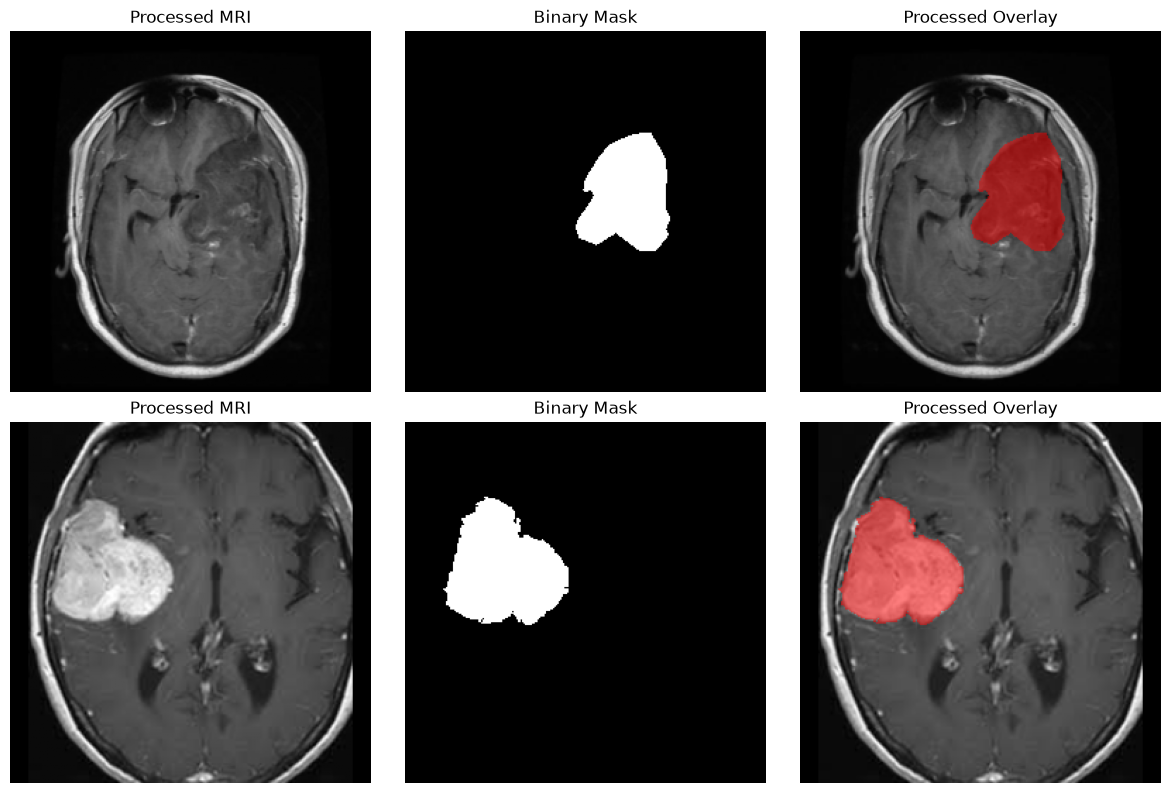

In [7]:

from PIL import Image, ImageOps
import numpy as np
import matplotlib.pyplot as plt

TARGET_SIZE = (256, 256)

def preprocess_preview(image_path, mask_path):

    # Load MRI as grayscale
    image = Image.open(image_path).convert("L")

    # Load mask and convert to binary
    mask = Image.open(mask_path).convert("L")
    mask = mask.point(lambda p: 255 if p >= 128 else 0)

    # Resize while preserving aspect ratio
    image_resized = ImageOps.contain(
        image,
        TARGET_SIZE,
        method=Image.Resampling.BILINEAR
    )

    mask_resized = ImageOps.contain(
        mask,
        TARGET_SIZE,
        method=Image.Resampling.NEAREST
    )

    # Create black 256x256 canvases
    image_canvas = Image.new("L", TARGET_SIZE, 0)
    mask_canvas = Image.new("L", TARGET_SIZE, 0)

    # Center images on canvases
    image_canvas.paste(
        image_resized,
        ((256 - image_resized.width) // 2,
         (256 - image_resized.height) // 2)
    )

    mask_canvas.paste(
        mask_resized,
        ((256 - mask_resized.width) // 2,
         (256 - mask_resized.height) // 2)
    )

    return np.array(image_canvas), np.array(mask_canvas)


# Find one standard and one non-standard sample
all_images = sorted([
    f for f in TRAIN_IMAGES.iterdir()
    if f.is_file()
])

standard_sample = next(
    f for f in all_images
    if Image.open(f).size == (512, 512)
)

nonstandard_sample = next(
    f for f in all_images
    if Image.open(f).size != (512, 512)
)

selected_samples = [standard_sample, nonstandard_sample]

fig, axes = plt.subplots(2, 3, figsize=(12, 8))

for i, image_path in enumerate(selected_samples):

    mask_path = TRAIN_MASKS / f"{image_path.stem}.png"

    processed_image, processed_mask = preprocess_preview(
        image_path, mask_path
    )

    overlay = np.stack(
        [processed_image] * 3,
        axis=-1
    )

    overlay[processed_mask > 0] = (
        overlay[processed_mask > 0] * 0.5
        + np.array([255, 0, 0]) * 0.5
    ).astype(np.uint8)

    axes[i, 0].imshow(processed_image, cmap="gray")
    axes[i, 0].set_title("Processed MRI")

    axes[i, 1].imshow(processed_mask, cmap="gray")
    axes[i, 1].set_title("Binary Mask")

    axes[i, 2].imshow(overlay)
    axes[i, 2].set_title("Processed Overlay")

    print("\nFilename:", image_path.name)
    print("Original dimensions:", Image.open(image_path).size)
    print("Processed image:", processed_image.shape)
    print("Processed mask:", processed_mask.shape)
    print("Mask unique values:", np.unique(processed_mask))

    for ax in axes[i]:
        ax.axis("off")

plt.tight_layout()
plt.show()


In [8]:

def prepare_model_input(image_path, mask_path):

    # Load grayscale MRI
    image = Image.open(image_path).convert("L")

    # Load grayscale mask
    mask = Image.open(mask_path).convert("L")

    # Binarize mask
    mask = mask.point(lambda p: 255 if p >= 128 else 0)

    # Resize while preserving aspect ratio
    image = ImageOps.contain(
        image, TARGET_SIZE,
        method=Image.Resampling.BILINEAR
    )

    mask = ImageOps.contain(
        mask, TARGET_SIZE,
        method=Image.Resampling.NEAREST
    )

    # Create fixed-size canvases
    image_canvas = Image.new("L", TARGET_SIZE, 0)
    mask_canvas = Image.new("L", TARGET_SIZE, 0)

    image_canvas.paste(
        image,
        ((256 - image.width) // 2,
         (256 - image.height) // 2)
    )

    mask_canvas.paste(
        mask,
        ((256 - mask.width) // 2,
         (256 - mask.height) // 2)
    )

    # Convert image to float32 and normalize
    image_array = np.array(
        image_canvas, dtype=np.float32
    ) / 255.0

    # Convert binary mask to 0 and 1
    mask_array = (
        np.array(mask_canvas) >= 128
    ).astype(np.float32)

    # Add channel dimension
    image_array = image_array[..., np.newaxis]
    mask_array = mask_array[..., np.newaxis]

    return image_array, mask_array


# Test using one training sample
image_path = standard_sample
mask_path = TRAIN_MASKS / f"{image_path.stem}.png"

X_sample, Y_sample = prepare_model_input(
    image_path, mask_path
)

print("MRI shape:", X_sample.shape)
print("Mask shape:", Y_sample.shape)

print("\nMRI data type:", X_sample.dtype)
print("Mask data type:", Y_sample.dtype)

print("\nMRI value range:", X_sample.min(), X_sample.max())
print("Mask unique values:", np.unique(Y_sample))

print("\nTumor pixels:", int(Y_sample.sum()))


MRI shape: (256, 256, 1)
Mask shape: (256, 256, 1)

MRI data type: float32
Mask data type: float32

MRI value range: 0.0 0.92156863
Mask unique values: [0. 1.]

Tumor pixels: 4094
